# Effort to calculate the ecosystem biomes defined in [Fay and McKinley (2014)](http://dx.doi.org/10.5194/essd-6-273-2014)
Currently not able to do for the ice regions because of deficiencies in the available ice data

In [102]:
import esm4ppe
import gfdl_utils as gu
import xarray as xr
from dask.diagnostics import ProgressBar

In [103]:
gu.core.get_allvars(esm4ppe.get_pp())

{'ocean_cobalt_sfc': ['dep_wet_po4',
  'dep_dry_nh4',
  'dep_wet_fed',
  'nh4_stf_gas',
  'dic_deltap',
  'dep_wet_nh4',
  'dep_dry_fed',
  'ffe_iceberg',
  'o2_sc_no',
  'dep_wet_no3',
  'dic_kw',
  'dic_stf_gas',
  'dep_dry_po4',
  'o2_csurf',
  'dic_sc_no',
  'o2_deltap',
  'pco2surf',
  'dep_dry_no3',
  'dep_dry_lith',
  'dic_csurf',
  'dep_wet_lith',
  'o2_kw',
  'o2_alpha',
  'o2_stf_gas'],
 'ice_daily': ['sithick', 'siconc'],
 'ocean_daily': ['MLD_003', 'zos', 'tos', 'sos'],
 'ocean_cobalt_omip_2d': ['limfediaz',
  'intppnitrate',
  'limndiat',
  'frfe',
  'limirrpico',
  'limpdiat',
  'limpmisc',
  'dpco2',
  'limfemisc',
  'epn100',
  'limnpico',
  'limnmisc',
  'limirrdiaz',
  'spco2',
  'intpbp',
  'intpcalcite',
  'eparag100',
  'limirrmisc',
  'epc100',
  'intdic',
  'intpppico',
  'intparag',
  'intpp',
  'intpn2',
  'fgo2',
  'intpbsi',
  'limfediat',
  'fgco2',
  'epsi100',
  'intppmisc',
  'fsfe',
  'epfe100',
  'intdoc',
  'epcalc100',
  'intppdiaz',
  'intpbn',
  'in

In [104]:
variables = ['tos','chlos','MLD_003']
ds = xr.Dataset()
for variable in variables:
    es = esm4ppe.esm4ppeObj(variable,'monthly').add_control()
    ds[variable] = es.control[variable]

Opening static... static opened.
Control present in zarr store... opening...
control opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Control present in zarr store... opening...
control opened.
Opening static... static opened.
Control present in zarr store... opening...
control opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [105]:
# convert chl from kg m-3 to mg m-3
ds['chlos'] *= 1e6
ds['chlos'].attrs['units']='mg m-3'

In [106]:
clim = xr.Dataset()
clim['MLD_003'] = ds['MLD_003'].groupby('time.year').max().mean('year')
clim['tos'] = ds['tos'].mean('time')
clim['chlos'] = ds['chlos'].groupby('time.month').mean().max('month')

grid = es.static

In [107]:
with ProgressBar():
    clim = clim.compute()
    grid = grid.compute()

[########################################] | 100% Completed | 64.36 s


In [108]:
condAtl = (grid['basin']==2)
condPac = (grid['basin']==3)
condInd = (grid['basin']==5)

condT_ge8 = (clim['tos']>=7)
condT_ge11 = (clim['tos']>=10)
condT_ge14 = (clim['tos']>=13)
condT_ge19 = (clim['tos']>=18)
condT_ge29 = (clim['tos']>=28)
condT_l14 = (clim['tos']<7)
condT_l14 = (clim['tos']<13)
condT_l29 = (clim['tos']<28)

condC_ge16 = (clim['chlos']>=0.16)
condC_ge25 = (clim['chlos']>=0.25)
condC_ge40 = (clim['chlos']>=0.4)
condC_l16 = (clim['chlos']<0.16)
condC_l25 = (clim['chlos']<0.25)
condC_l40 = (clim['chlos']<0.4)
condC_l40 = (clim['chlos']<0.7)

condM_le125 = (clim['MLD_003']<=125)
condM_le150 = (clim['MLD_003']<=150)
condM_g125 = (clim['MLD_003']>125)
condM_g150 = (clim['MLD_003']>150)

condNH = (grid['geolat']>0)
condSH = (grid['geolat']<0)
condEq15 = ((grid['geolat']<=15) & (grid['geolat']>=-15))
condEq10 = ((grid['geolat']<=10) & (grid['geolat']>=-10))

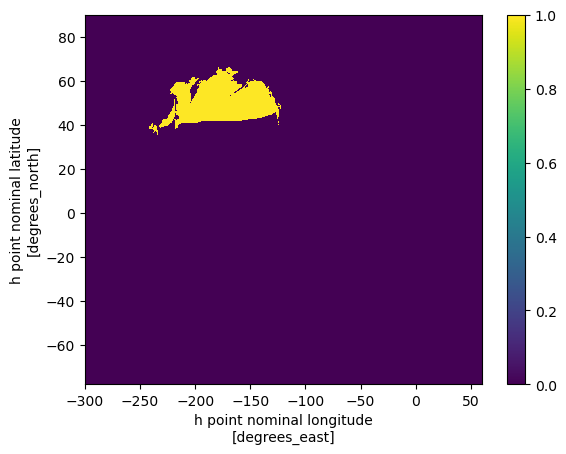

In [109]:
condnow = condNH & condPac & condT_l14 & condC_ge25
cond['N Pacific SPSS'] = condnow
condnow.plot()

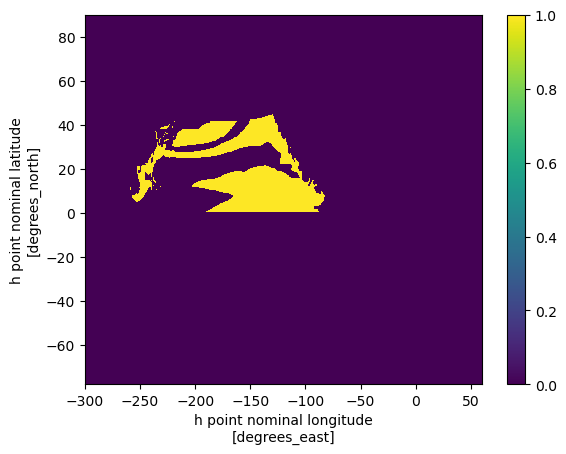

In [110]:
condnow = ~condnow & condNH & condPac & (condT_ge11 & condT_l29) & ((condC_ge16 & condC_l40) | condM_g125)
cond['NH Pac STSS'] = condnow
condnow.plot()

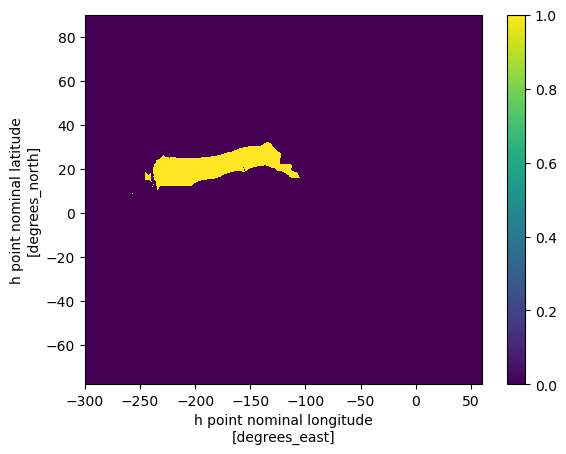

In [111]:
condnow = ~condnow & condNH & condPac & (condT_ge14 & condT_l29) & condC_l16 & condM_le125
cond['NH Pac STPS'] = condnow
condnow.plot()

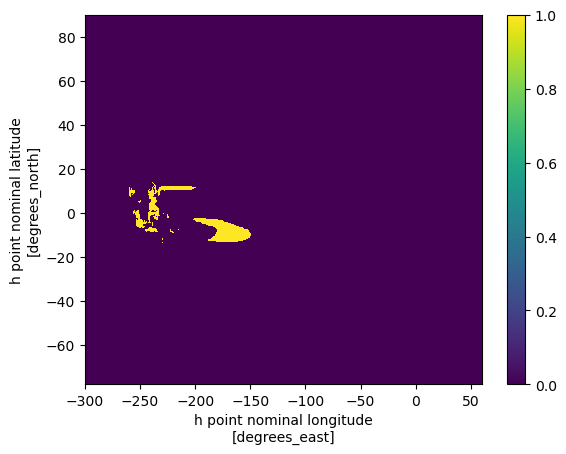

In [112]:
condnow = ~condnow & condEq15 & condPac & condT_ge29 & condC_l25
cond['West Pacific EQU'] = condnow
condnow.plot()

In [99]:
cond = {}
cond['N Pacific SPSS'] = (grid['basin']==3) & (clim['tos']<14) & (clim['chlos']>=0.25)
cond['N Atlantic SPSS'] = (grid['basin']==2) & (clim['tos']<14) & (clim['chlos']>=0.4)
cond['NH Pac STSS'] = (grid['basin']==3) & (grid['geolat']>0) & ((clim['tos']>=11) & (clim['tos']<29)) & (((clim['chlos']>=0.16) & (clim['chlos']<0.4)) | (clim['MLD_003']>125))
cond['NH Atl STSS'] = (grid['basin']==2) & (grid['geolat']>0) & ((clim['tos']>=11) & (clim['tos']<29)) & (((clim['chlos']>=0.16) & (clim['chlos']<0.4)) | (clim['MLD_003']>125))
cond['NH Pac STPS'] = (grid['basin']==3) & (grid['geolat']>0) &((clim['tos']>=14) & (clim['tos']<29)) & ((clim['chlos']<0.16) & (clim['MLD_003']>125))
cond['NH Atl STPS'] = (grid['basin']==2) & (grid['geolat']>0) &((clim['tos']>=14) & (clim['tos']<29)) & ((clim['chlos']<0.16) & (clim['MLD_003']>125))
cond['IND STPS'] = (grid['basin']==5) & (clim['tos']>=11) & (clim['chlos']<0.25)
cond['West Pacific EQU'] = (grid['basin']==3) & (clim['tos']>=29) & (clim['chlos']<0.25) & ((grid['geolat']<=15) & (grid['geolat']>=-15))
cond['East Pacific EQU'] = (grid['basin']==3) & ((clim['tos']>=19) & (clim['tos']<29)) & ((clim['chlos']>=0.16) & (clim['chlos']<0.7)) & ((grid['geolat']<=10) & (grid['geolat']>=-10))
cond['Atlantic EQU'] = (grid['basin']==2) & ((clim['tos']>=19) & (clim['tos']<29)) & ((clim['chlos']>=0.16) & (clim['chlos']<0.7)) & ((grid['geolat']<=10) & (grid['geolat']>=-10))
cond['SH STPS'] = (grid['geolat']<0) & (clim['tos']>=8) & (clim['chlos']<0.25) & (clim['MLD_003']<=150)
cond['SH STSS'] = (grid['geolat']<0) & (clim['tos']>=8) & ((clim['chlos']>=0.16) | (clim['MLD_003']>150))
cond['SH SPSS'] = (grid['geolat']<0) & (clim['tos']<8)

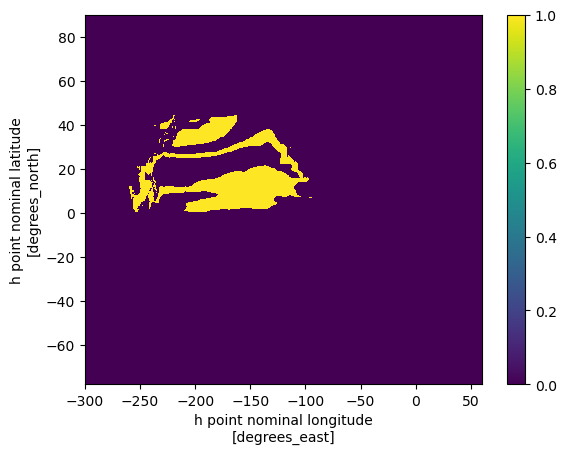

In [101]:
(cond['NH Pac STSS']).plot()